In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import schemdraw
import schemdraw.elements as elm
from IPython.display import Audio, display

# Affichage vectoriel haute définition dans VS Code
%config InlineBackend.figure_format = 'svg'

# --- PARAMÈTRES DE VOTRE CIRCUIT ESP32-C3 ---
VCC = 3.3                 # Tension logique ESP32-C3 (Volts)
SAMPLE_RATE = 22050       # Fréquence d'échantillonnage de votre code C++ (Hz)
PWM_FREQ = 44100          # Fréquence porteuse PWM dans setup() (Hz)

# Composants du filtre passe-bas RC (Sortie GPIO 7)
R_FILT = 1000.0           # 1 kOhm
C_FILT = 100e-9           # 100 nF
C_COUP = 10e-6            # 10 uF (condensateur de liaison audio)

# Composants d'entrée analogique (Potentiomètres)
R_POT = 100e3             # 100 kOhm
C_POT = 100e-9            # 100 nF (filtrage bruit ADC)

print(f"Fréquence de coupure filtre Audio : {1 / (2 * np.pi * R_FILT * C_FILT):.1f} Hz")
print(f"Fréquence de coupure filtre Potentiomètre : {1 / (2 * np.pi * (R_POT/4) * C_POT):.1f} Hz")


Fréquence de coupure filtre Audio : 1591.5 Hz
Fréquence de coupure filtre Potentiomètre : 63.7 Hz


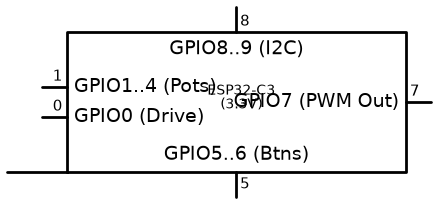

AttributeError: GPIO0 not defined in Element

In [4]:
with schemdraw.Drawing() as d:
    d.config(fontsize=10, unit=2.8)

    # 1. Bloc ESP32-C3
    esp = elm.Ic(pins=[
        elm.IcPin(name="GPIO0 (Drive)", side="left", pin="0"),
        elm.IcPin(name="GPIO1..4 (Pots)", side="left", pin="1"),
        elm.IcPin(name="GPIO5..6 (Btns)", side="bottom", pin="5"),
        elm.IcPin(name="GPIO7 (PWM Out)", side="right", pin="7"),
        elm.IcPin(name="GPIO8..9 (I2C)", side="top", pin="8"),
    ], edgepadW=1.3, edgepadH=0.8).label("ESP32-C3\n(3.3V)", loc="center")
    d += esp

    # 2. Entrée Potentiomètre 100k + Condo 100nF (à gauche)
    d += elm.Line().left(1.2).at(esp.GPIO0)
    d.push()
    d += elm.Capacitor().down().label("100nF", loc="bottom")
    d += elm.Ground()
    d.pop()
    d += (pot := elm.Potentiometer().left().label("Pot 100kΩ", loc="top"))
    d += elm.Vdd().at(pot.tap).label("3.3V")
    d += elm.Ground().at(pot.end)

    # 3. Étage de sortie Audio PWM (à droite)
    d += elm.Line().right(1.2).at(esp.GPIO7)
    d += elm.Resistor().right().label(f"R_filt\n{R_FILT/1000:.1f}kΩ")
    d.push()
    d += elm.Capacitor().down().label(f"C_filt\n{C_FILT*1e9:.0f}nF", loc="bottom")
    d += elm.Ground()
    d.pop()
    d += elm.Capacitor().right().label(f"C_coup\n{C_COUP*1e6:.0f}µF")
    d += elm.Dot(open=True).label("Sortie Audio\n(Jack 3.5mm)", loc="right")

    # 4. Écran OLED I2C (en haut)
    d += elm.Line().up(1.0).at(esp.GPIO8)
    d += elm.Dot(open=True).label("Vers OLED SSD1306 (SDA/SCL)", loc="right")


In [5]:
fc = 1 / (2 * np.pi * R_FILT * C_FILT)
system = signal.TransferFunction(, [R_FILT * C_FILT, 1])

freqs = np.logspace(1, 5, 1000)
w, mag, phase = signal.bode(system, w=freqs * 2 * np.pi)

# Atténuation exacte à la fréquence porteuse PWM (44.1 kHz)
_, mag_pwm, _ = signal.bode(system, w=[PWM_FREQ * 2 * np.pi])

plt.figure(figsize=(9, 3.5))
plt.semilogx(freqs, mag, linewidth=2, color="#1f77b4", label="Réponse du filtre RC")
plt.axvline(fc, color="green", linestyle="--", label=f"Coupure (-3 dB) : {fc:.0f} Hz")
plt.axvline(PWM_FREQ, color="red", linestyle=":", label=f"Porteuse PWM ({PWM_FREQ/1000:.1f} kHz) : {mag_pwm:.1f} dB")

plt.title("Atténuation du bruit PWM et bande passante audio")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Gain (dB)")
plt.ylim(-45, 5)
plt.grid(True, which="both", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()


SyntaxError: invalid syntax (1104060163.py, line 2)

In [ ]:
duree = 2.0
fs_sim = PWM_FREQ * 4  # Sur-échantillonnage pour simuler le découpage PWM réel
t = np.linspace(0, duree, int(fs_sim * duree), endpoint=False)

# 1. Génération d'une note de basse (55 Hz = La1)
freq_basse = 55.0
saw = 2.0 * (t * freq_basse - np.floor(0.5 + t * freq_basse))

# 2. Modulation PWM (signal carré 0V / 3.3V à 44.1 kHz)
porteuse = 2.0 * (t * PWM_FREQ - np.floor(0.5 + t * PWM_FREQ))
pwm_signal = np.where(saw > porteuse, VCC, 0.0)

# 3. Filtrage analogique RC + suppression composante continue (C_coup)
b, a = signal.bilinear(, [R_FILT * C_FILT, 1], fs=fs_sim)
audio_lisse = signal.lfilter(b, a, pwm_signal) - (VCC / 2.0)

# Tracé zoomé sur 20 millisecondes pour voir l'effet du condensateur C_filt
zoom = int(0.02 * fs_sim)
plt.figure(figsize=(9, 3))
plt.plot(t[:zoom] * 1000, pwm_signal[:zoom], alpha=0.25, color="gray", label="Signal brut GPIO 7 (PWM 0-3.3V)")
plt.plot(t[:zoom] * 1000, audio_lisse[:zoom] + (VCC/2), color="#d62728", linewidth=2, label="Après filtre RC (R1 + C1)")
plt.title("Zoom oscilloscope (20 ms) : Lissage du signal PWM")
plt.xlabel("Temps (ms)")
plt.ylabel("Tension (V)")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Lecteur audio interactif (ré-échantillonné à 22 050 Hz comme votre ESP32)
audio_22k = signal.resample(audio_lisse, int(duree * SAMPLE_RATE))
display(Audio(audio_22k, rate=SAMPLE_RATE))
